<a href="https://colab.research.google.com/github/keyaa21/Machine-Learning-Using-Python/blob/main/CustomerSegmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


In [2]:
#1. Load the dataset

df = pd.read_csv('Mall_Customers.csv')

#2. Inspect the structure the dataset

print("Dataset shape:",df.shape)
print(df.head())
print(df.info())

Dataset shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [3]:
#3. Select two features and then scale those features

X = df[['Annual Income (k$)','Spending Score (1-100)']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

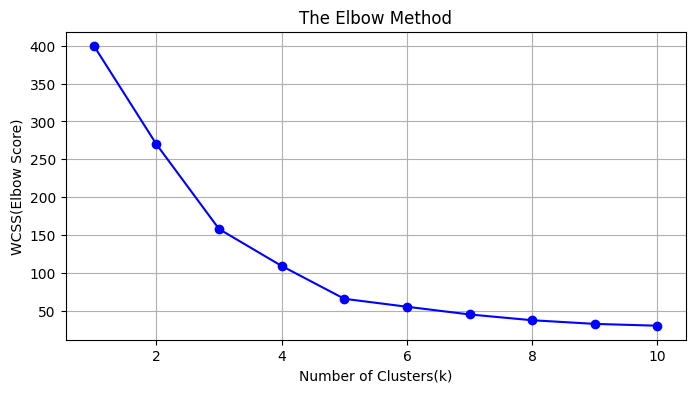

In [9]:
#4. Implementing KMeans Clustering

wcss = []  # Within-Cluster Sum of Squares

# Test cluster sizes from 1 to 10

for i in range(1,11):
  kmeans = KMeans(n_clusters = i, random_state = 42, n_init = 10,init = 'k-means++')
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_) # as k increases error drops

# Plot the elbow curve

plt.figure(figsize=(8,4))
plt.plot(range(1,11),wcss,marker = 'o',linestyle = '-',color = 'b')
plt.title("The Elbow Method")
plt.xlabel('Number of Clusters(k)')
plt.ylabel('WCSS(Elbow Score)')
plt.grid(True)
plt.show()

In [10]:
# 1. Instantiate KMeans with 5 clusters
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)

# 2. Fit and predict cluster labels for each customer
cluster_labels = kmeans.fit_predict(X_scaled)

# 3. Add the cluster labels back to our original DataFrame
df['Cluster'] = cluster_labels

print(df.head(10))

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1    Male   19                  15                      39        4
1           2    Male   21                  15                      81        2
2           3  Female   20                  16                       6        4
3           4  Female   23                  16                      77        2
4           5  Female   31                  17                      40        4
5           6  Female   22                  17                      76        2
6           7  Female   35                  18                       6        4
7           8  Female   23                  18                      94        2
8           9    Male   64                  19                       3        4
9          10  Female   30                  19                      72        2


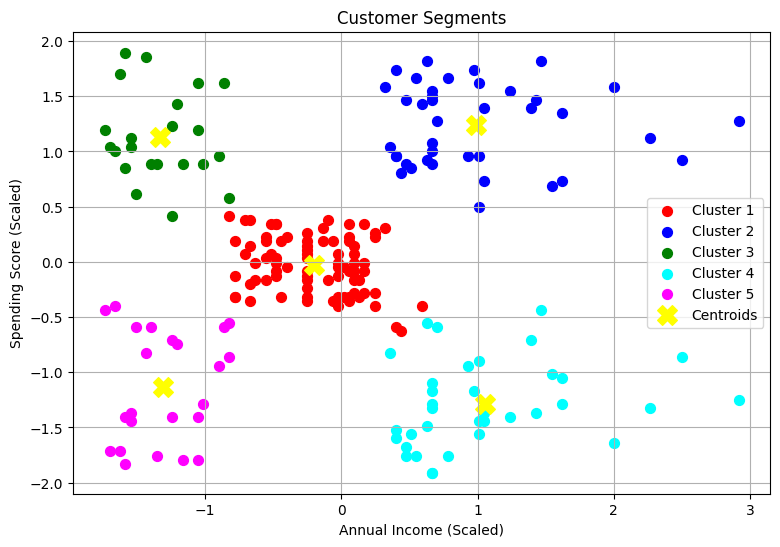

In [11]:
plt.figure(figsize=(9, 6))

# Plot each cluster with a different color
plt.scatter(X_scaled[cluster_labels == 0, 0], X_scaled[cluster_labels == 0, 1], s=50, c='red', label='Cluster 1')
plt.scatter(X_scaled[cluster_labels == 1, 0], X_scaled[cluster_labels == 1, 1], s=50, c='blue', label='Cluster 2')
plt.scatter(X_scaled[cluster_labels == 2, 0], X_scaled[cluster_labels == 2, 1], s=50, c='green', label='Cluster 3')
plt.scatter(X_scaled[cluster_labels == 3, 0], X_scaled[cluster_labels == 3, 1], s=50, c='cyan', label='Cluster 4')
plt.scatter(X_scaled[cluster_labels == 4, 0], X_scaled[cluster_labels == 4, 1], s=50, c='magenta', label='Cluster 5')

# Plot the center points (centroids) of each cluster
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='yellow', marker='X', label='Centroids')

plt.title('Customer Segments')
plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.legend()
plt.grid(True)
plt.show()